# NYC 311 · Hurricane Ida — Qdrant + Neo4j, starting from the clean dataset

**City Brain · citizen-calls layer.** This notebook starts from the **clean file `nyc311_ida_clean.csv`** (the cleaned 311 calls, one row per call, with the same `point_id` Qdrant uses). It stores the calls in **Qdrant** (similarity: *"which past calls look like this one?"*) and in **Neo4j** (explanation: *"why, and what was going on around it?"*), then **combines both**.

**Part A: Qdrant (sections 1–4)**

1. **Load the clean dataset**
2. **Visual exploration** of the storm night (optional, uses only the clean file)
3. **Build the Qdrant records**: one generic `text` to embed (incident type + severity) + a small `payload`
4. *(off until you set `RUN_QDRANT = True`)* embed and upload to **your Qdrant Cloud cluster**

**Part B: Neo4j graph and the combined explanation (sections 5–10)**

5. **Build the graph tables** (surge waves, hours, zones, boroughs) in pandas
6. **Connect** to your Neo4j (Aura) instance
7. **Load** the graph *(off until `RUN_NEO4J = True`)*
8. **Ask the graph questions** in Cypher
9. **Explain one call** (a sentence and a picture)
10. **Combine**: a new situation → Qdrant finds similar past calls → Neo4j explains each one *(off until `RUN_COMBINE = True`)*

### Switches (everything that writes to a cloud database is **off** by default)

| Switch | Where | What it does |
|---|---|---|
| `RUN_QDRANT` | section 4 cell | embed and upload the points to Qdrant |
| `RUN_NEO4J` | first constants cell (section 0) | connect, load the graph, run the Cypher sections |
| `RUN_COMBINE` | first constants cell (section 0) | section 10: query Qdrant and explain with Neo4j |
| `CLEAR_GRAPH` / `RECREATE` | constants cell / section 4 cell | delete what this notebook created earlier in Neo4j / the Qdrant collection first |

### Design decision: what goes in the vector and what goes in the payload

| Goes where | What | Why |
|---|---|---|
| **Vector** (embedded text) | A generated sentence per call: **incident type + severity** (how many similar calls in the previous hour, city-wide) | The City Brain should recognise *"a situation like this one"*, not *"something in Queens on a Thursday"*. Place, date and storm name are left out so the same vectors work for any city, event or data source. |
| **Payload** (stored next to the vector) | `incident_type`, `call_type`, `call_group`, `surge_level`, `city_recent_60m` | Small and general. |
| **Optional context** (`INCLUDE_CONTEXT = True`) | `ts`, `borough`, `zip_code`, `location`, `zone_id`, `phase`, ... | Off by default. Turn it on only if you want filters like *"within 3 km"* or *"last 2 hours"*. It never goes into the vector. |
| **Neo4j graph** | where, when, which surge wave, what else surged at the same time | The context the vectors deliberately leave out. |

The two stores are joined by one key: **`point_id`** (Qdrant point id = `Call.id` in Neo4j).

## 0 · Setup

In [1]:
# Colab already ships pandas, numpy, matplotlib, networkx. Nothing to install for sections 1-3 and 5.
# (Section 4 installs sentence-transformers + qdrant-client, section 6 installs neo4j, when you turn them on.)
import os, sys, json, uuid, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import networkx as nx                      # used by the Neo4j part (already in Colab)
from collections import Counter
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Running in Colab: True


In [2]:
# ---- switches for the Neo4j part (section 4 has its own RUN_QDRANT switch) -------
RUN_NEO4J    = True      # sections 6-9: load the graph into Neo4j and query it
RUN_COMBINE  = True      # section 10: Qdrant similarity + Neo4j explanation (needs sections 4 and 7 done)
CLEAR_GRAPH  = True      # True = first delete the nodes THIS notebook created earlier in Neo4j (tagged ds = DS)

# ---- constants -------------------------------------------------------------
TZ          = "America/New_York"                       # the CSV is in NYC local time
STORM_START = pd.Timestamp("2021-09-01 18:00", tz=TZ)  # Ida night window used in notebook 05
STORM_END   = pd.Timestamp("2021-09-02 06:00", tz=TZ)

# False = generic records (incident type + severity only).
# True  = also store time / borough / ZIP / position in the Qdrant payload (never in the embedded text).
INCLUDE_CONTEXT = True

# ---- chart style: one fixed colour per call group (categorical slots 1-3) ---
GROUP_ORDER  = ["Sewer backup", "Other flooding", "Traffic signal failure"]
GROUP_COLORS = {"Sewer backup": "#2a78d6", "Other flooding": "#eb6834", "Traffic signal failure": "#1baf7a"}
INK, INK2, SURF, GRIDC = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRIDC, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "font.size": 10,
})

def shade_storm(ax):
    ax.axvspan(STORM_START, STORM_END, color="#9a9992", alpha=0.16, lw=0, zorder=0)

# ---- graph constants (sections 5-10) ----
EPISODE_MIN  = 50         # >= this many flood calls in an hour = "busy hour"
MERGE_GAP_H  = 2          # busy hours at most this far apart belong to the same wave
DS           = "nyc311-ida"                 # tag on every Neo4j node we create
BLUE         = "#2a78d6"

## 1 · Load the clean dataset

Upload `nyc311_ida_clean.csv` in the dialog (Colab), or put it next to the notebook. From Google Drive, set `CLEAN_PATH = "/content/drive/MyDrive/.../nyc311_ida_clean.csv"`.

The file must have one row per call with at least: `created_at`, `call_type`, `call_group`, `call_label`, `incident_type`, `borough`, `latitude`, `longitude`, `has_geo`, `phase`, `zone_id`, `ts`.
Anything an older export lacks (`city_recent_60m`, `date`, `hour`, `dow`, `zip_code`, ...) is rebuilt or filled in below; `surge_level`, `text` and `point_id` are checked in section 3.

In [3]:
CLEAN_PATH = "nyc311_ida_clean.csv"

if not os.path.exists(CLEAN_PATH):
    if IN_COLAB:
        from google.colab import files
        print("Select nyc311_ida_clean.csv ...")
        up = files.upload()
        CLEAN_PATH = next(iter(up))
    else:
        raise FileNotFoundError(f"{CLEAN_PATH} not found - set CLEAN_PATH to the clean file.")

df = pd.read_csv(CLEAN_PATH, dtype={"zip_code": "string", "zone_id": "string"})

CORE = ["created_at", "call_type", "call_group", "call_label", "incident_type", "borough", "latitude", "longitude",
        "has_geo", "phase", "zone_id", "ts"]
missing = [c for c in CORE if c not in df.columns]
assert not missing, f"the clean file is missing these columns: {missing}"

df["created_at"] = pd.to_datetime(df.created_at, utc=True).dt.tz_convert(TZ)
df = df.sort_values("created_at", kind="stable").reset_index(drop=True)
df["has_geo"] = df.has_geo.astype(bool)
df["phase"]   = pd.Categorical(df.phase, categories=["pre_storm", "storm_night", "aftermath"], ordered=True)

# columns an older export may not have
if "date" not in df: df["date"] = df.created_at.dt.strftime("%Y-%m-%d")
if "hour" not in df: df["hour"] = df.created_at.dt.hour
if "dow"  not in df: df["dow"]  = df.created_at.dt.day_name()
if "zip_code" not in df: df["zip_code"] = pd.Series(pd.NA, index=df.index, dtype="string")
for c in ("zone_recent_60m", "borough_recent_60m"):
    if c not in df: df[c] = 0
if "city_recent_60m" not in df:
    out = pd.Series(0, index=df.index, dtype="int64")      # other calls of the same incident type in the previous 60 min, city-wide
    for _, g in df.groupby("incident_type"):
        tt = g.created_at.dt.tz_convert("UTC").dt.tz_localize(None).to_numpy()
        out.loc[g.index] = np.searchsorted(tt, tt, side="right") - np.searchsorted(tt, tt - np.timedelta64(60, "m"), side="left") - 1
    df["city_recent_60m"] = out
    print("city_recent_60m was missing: rebuilt from the timestamps")

print(f"{len(df):,} calls  |  {df.created_at.min():%d %b %H:%M} -> {df.created_at.max():%d %b %H:%M}  |  "
      f"{int(df.has_geo.sum()):,} with coordinates  |  phases: {df.phase.value_counts().sort_index().to_dict()}")
df[["created_at", "call_label", "incident_type", "borough", "phase", "zone_id", "city_recent_60m"]].head()

Select nyc311_ida_clean.csv ...


Saving nyc311_ida_clean.csv to nyc311_ida_clean.csv
6,273 calls  |  31 Aug 00:19 -> 03 Sep 23:55  |  6,026 with coordinates  |  phases: {'pre_storm': 283, 'storm_night': 2496, 'aftermath': 3494}


,created_at,call_label,incident_type,borough,phase,zone_id,city_recent_60m
0,2021-08-31 00:19:00-04:00,Traffic signal failure,traffic_signal_failure,Manhattan,pre_storm,unknown,0
1,2021-08-31 01:37:00-04:00,Traffic signal failure,traffic_signal_failure,Brooklyn,pre_storm,unknown,0
2,2021-08-31 01:44:00-04:00,Traffic signal failure,traffic_signal_failure,Brooklyn,pre_storm,unknown,1
3,2021-08-31 02:24:00-04:00,Traffic signal failure,traffic_signal_failure,Manhattan,pre_storm,unknown,2
4,2021-08-31 04:35:00-04:00,Traffic signal failure,traffic_signal_failure,Bronx,pre_storm,unknown,0


## 2 · Visual exploration (from the clean file)

### 2.1 When — calls per hour

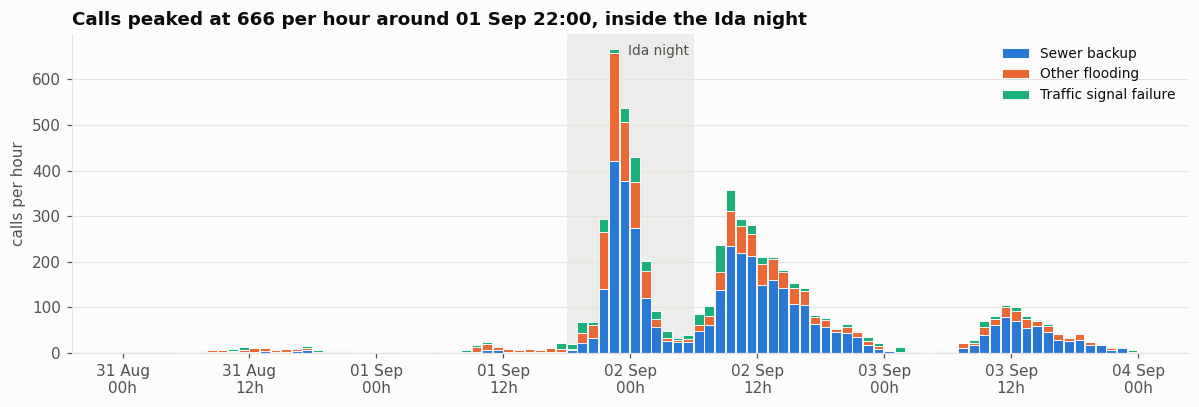

call_group,Sewer backup,Other flooding,Traffic signal failure
phase,,,
pre_storm,71,130,82
storm_night,1524,742,230
aftermath,2435,711,348


In [4]:
hourly = (df.groupby([pd.Grouper(key="created_at", freq="h"), "call_group"]).size()
            .unstack(fill_value=0).reindex(columns=GROUP_ORDER, fill_value=0))
total = hourly.sum(axis=1)
peak_t, peak_n = total.idxmax(), int(total.max())

fig, ax = plt.subplots(figsize=(11, 3.8))
shade_storm(ax)
bottom = np.zeros(len(hourly))
for g in GROUP_ORDER:
    ax.bar(hourly.index, hourly[g], bottom=bottom, width=1 / 24 * 0.92, align="edge",
           color=GROUP_COLORS[g], edgecolor=SURF, linewidth=0.6, label=g)
    bottom += hourly[g].to_numpy()
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12], tz=hourly.index.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Hh", tz=hourly.index.tz))
ax.set_ylabel("calls per hour")
ax.set_title(f"Calls peaked at {peak_n} per hour around {peak_t:%d %b %H:%M}, inside the Ida night")
ax.text(STORM_END - pd.Timedelta(minutes=30), ax.get_ylim()[1] * 0.97, "Ida night", color=INK2, fontsize=9, va="top", ha="right")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

# table view of the same numbers (colour is never the only carrier of meaning)
display(pd.crosstab(df.phase, df.call_group).reindex(columns=GROUP_ORDER))

The Ida night against the **previous night** (same 12 hours, one day earlier):

In [5]:
prev  = (df.created_at >= STORM_START - pd.Timedelta(days=1)) & (df.created_at < STORM_END - pd.Timedelta(days=1))
night = df.phase.eq("storm_night")
cmp = pd.DataFrame({"previous night": df[prev].call_group.value_counts(),
                    "Ida night":      df[night].call_group.value_counts()}).reindex(GROUP_ORDER).fillna(0).astype(int)
cmp["x more calls"] = (cmp["Ida night"] / cmp["previous night"].clip(lower=1)).round(1)
cmp

,previous night,Ida night,x more calls
call_group,,,
Sewer backup,4,1524,381.0
Other flooding,13,742,57.1
Traffic signal failure,15,230,15.3


### 2.2 Where — boroughs and call types on the Ida night

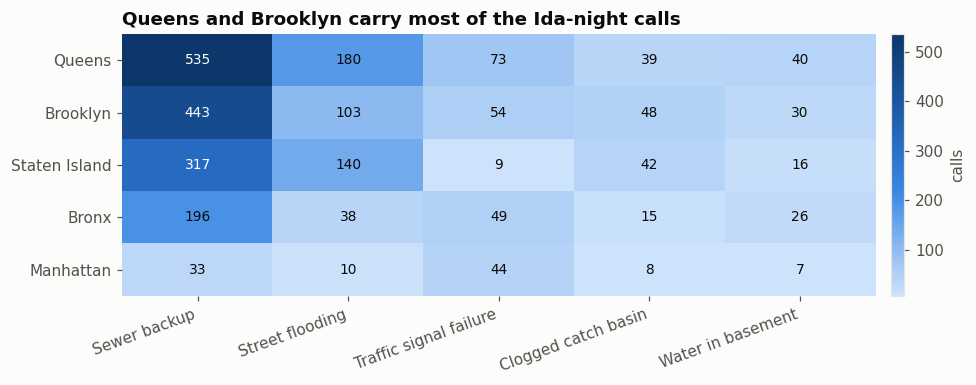

In [6]:
night_df = df[df.phase.eq("storm_night")]
order_b = night_df.borough.value_counts().index.tolist()
order_t = night_df.call_label.value_counts().index.tolist()
hm = pd.crosstab(night_df.borough, night_df.call_label).reindex(index=order_b, columns=order_t, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(hm.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns, rotation=20, ha="right")
ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index)
for (i, j), v in np.ndenumerate(hm.values):
    ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=9,
            color="white" if v > hm.values.max() * 0.45 else INK)
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title(f"{order_b[0]} and {order_b[1]} carry most of the Ida-night calls")
fig.colorbar(im, ax=ax, label="calls", fraction=0.03, pad=0.02)
plt.tight_layout(); plt.show()

### 2.3 Does the storm hit all boroughs at once?

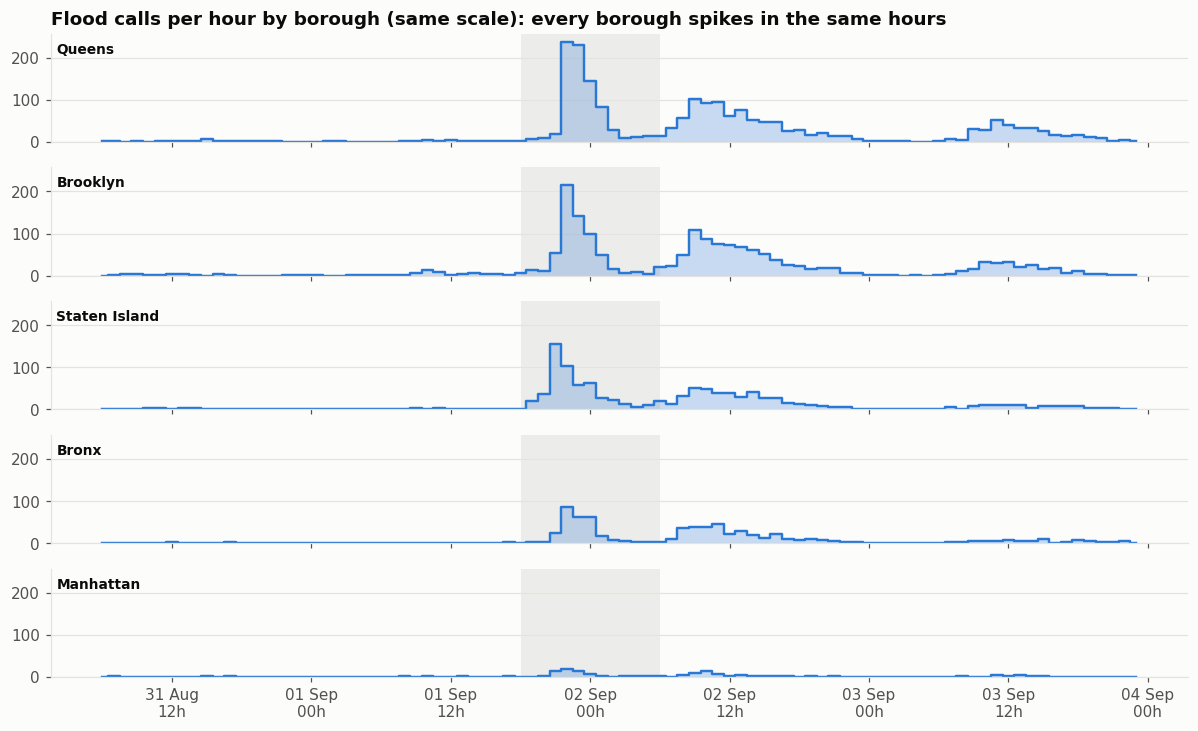

In [7]:
flood_h = (df[df.incident_type.eq("flood")]
             .groupby([pd.Grouper(key="created_at", freq="h"), "borough"]).size().unstack(fill_value=0))
boroughs = flood_h.sum().sort_values(ascending=False).index.tolist()
ymax = flood_h.max().max() * 1.08

fig, axes = plt.subplots(len(boroughs), 1, figsize=(11, 1.35 * len(boroughs)), sharex=True, sharey=True)
for ax, b in zip(axes, boroughs):
    shade_storm(ax)
    ax.fill_between(flood_h.index, flood_h[b], step="mid", color="#2a78d6", alpha=0.25, lw=0)
    ax.step(flood_h.index, flood_h[b], where="mid", color="#2a78d6", lw=1.6)
    ax.set_ylim(0, ymax)
    ax.text(0.005, 0.82, b, transform=ax.transAxes, fontsize=9, color=INK, fontweight="bold")
    ax.grid(axis="x", visible=False)
axes[0].set_title("Flood calls per hour by borough (same scale): every borough spikes in the same hours")
axes[-1].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12], tz=flood_h.index.tz))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Hh", tz=flood_h.index.tz))
plt.tight_layout(); plt.show()

### 2.4 Map — before, during, after (no basemap, plain lon/lat)

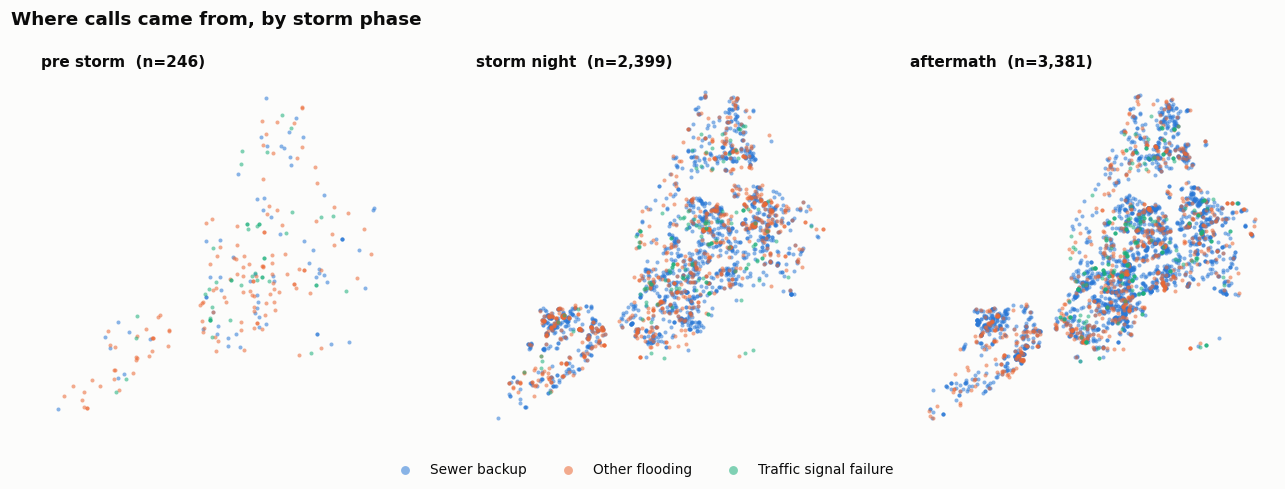

In [8]:
geo = df[df.has_geo]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), sharex=True, sharey=True)
for ax, ph in zip(axes, ["pre_storm", "storm_night", "aftermath"]):
    sub = geo[geo.phase.eq(ph)]
    for g in GROUP_ORDER:
        s = sub[sub.call_group.eq(g)]
        ax.scatter(s.longitude, s.latitude, s=7, color=GROUP_COLORS[g], alpha=0.55, lw=0, label=g)
    ax.set_title(f"{ph.replace('_', ' ')}  (n={len(sub):,})", fontsize=10)
    ax.set_aspect(1 / np.cos(np.deg2rad(40.7)))
    ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    for s_ in ax.spines.values(): s_.set_visible(False)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, fontsize=9, markerscale=2.2)
fig.suptitle("Where calls came from, by storm phase", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(rect=[0, 0.07, 1, 0.95]); plt.show()

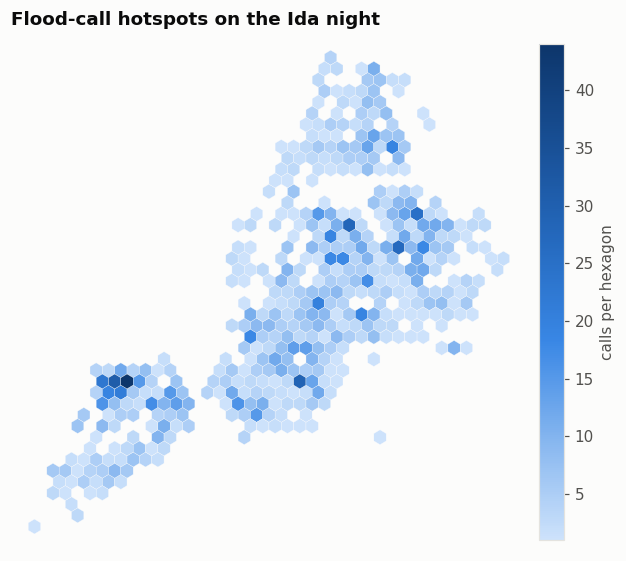

,calls,borough,lat,lon
zone_id,,,,
z4074_-7382,31,Queens,40.7440,-73.8162
z4062_-7414,31,Staten Island,40.6282,-74.1330
z4062_-7416,28,Staten Island,40.6276,-74.1542
z4062_-7394,23,Brooklyn,40.6249,-73.9353
z4073_-7390,22,Queens,40.7381,-73.8958
z4061_-7416,21,Staten Island,40.6145,-74.1530
z4061_-7411,19,Staten Island,40.6129,-74.1048
z4076_-7388,19,Queens,40.7644,-73.8771


In [9]:
fl = geo[geo.phase.eq("storm_night") & geo.incident_type.eq("flood")]
fig, ax = plt.subplots(figsize=(6.4, 5.2))
hb = ax.hexbin(fl.longitude, fl.latitude, gridsize=38, mincnt=1, cmap=SEQ, linewidths=0.2, edgecolors=SURF)
ax.set_aspect(1 / np.cos(np.deg2rad(40.7))); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
for s_ in ax.spines.values(): s_.set_visible(False)
ax.set_title("Flood-call hotspots on the Ida night")
fig.colorbar(hb, ax=ax, label="calls per hexagon", fraction=0.04, pad=0.02)
plt.tight_layout(); plt.show()

top = (fl.groupby("zone_id").agg(calls=("ts", "size"), borough=("borough", lambda s: s.mode().iat[0]),
                                 lat=("latitude", "mean"), lon=("longitude", "mean"))
         .sort_values("calls", ascending=False).head(8).round(4))
top

### 2.5 The surge feature — what the vector will learn from

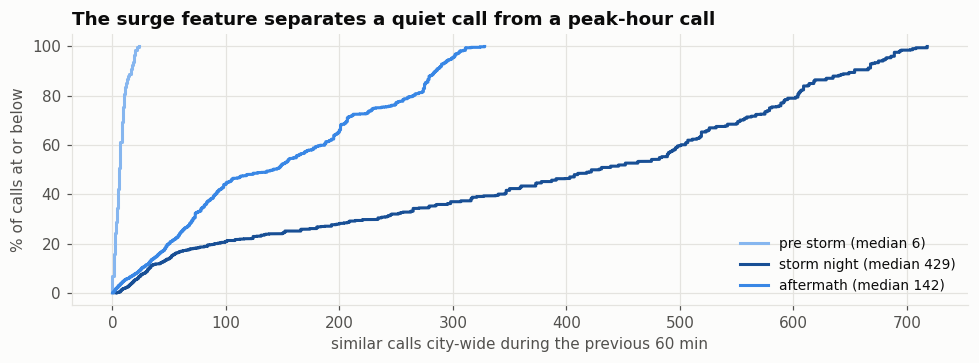

In [10]:
PHASE_COLORS = {"pre_storm": "#86b6ef", "storm_night": "#184f95", "aftermath": "#3987e5"}   # one blue ramp, light -> dark
med = df.groupby("phase", observed=True).city_recent_60m.median()

fig, ax = plt.subplots(figsize=(9, 3.4))
for ph, c in PHASE_COLORS.items():
    v = np.sort(df.loc[df.phase.eq(ph), "city_recent_60m"].to_numpy())
    y = np.arange(1, len(v) + 1) / len(v) * 100
    ax.step(v, y, where="post", color=c, lw=2, label=f"{ph.replace('_', ' ')} (median {med[ph]:.0f})")
ax.set_xlabel("similar calls city-wide during the previous 60 min")
ax.set_ylabel("% of calls at or below")
ax.set_title("The surge feature separates a quiet call from a peak-hour call")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

## 3 · Build the Qdrant records

Each call becomes one **point**:

* `id` – deterministic UUID (re-running never creates duplicates in Qdrant)
* `text` – the sentence that will be embedded: **incident type + city-wide severity only** (no date, borough, ZIP, place or storm name)
* `payload` – small and general by default. With `INCLUDE_CONTEXT = True` it also carries time and position (position as `{"lat", "lon"}` so Qdrant's **geo filters** work)

Missing values are simply left out of the payload (no `NaN`s in JSON).

In [11]:
# severity wording (so a peak-hour call "sounds" different from a quiet one) - based on the city-wide count
SURGE_BINS   = [-1, 4, 29, 99, 299, np.inf]
SURGE_LABELS = ["isolated report", "small cluster", "busy period", "heavy surge", "extreme surge"]

def make_text(r):
    # deliberately generic: no date, borough, ZIP, place or storm name
    return (f"{r.call_label} reported. Situation: {r.surge_level}, "
            f"{r.city_recent_60m} similar calls city-wide during the previous hour.")

# The clean file normally already has surge_level, text and point_id (the same ones Qdrant uses): they are kept as they are.
# Anything missing is rebuilt with the same rules.
if "surge_level" not in df:
    df["surge_level"] = pd.cut(df.city_recent_60m, SURGE_BINS, labels=SURGE_LABELS).astype(str)
    print("surge_level was missing: rebuilt")
if "text" not in df:
    df["text"] = df.apply(make_text, axis=1)
    print("text was missing: rebuilt")
if "point_id" not in df:
    key = (df.created_at.dt.strftime("%Y-%m-%dT%H:%M:%S") + "|" + df.call_type + "|" + df.borough.fillna("") + "|"
           + df.latitude.astype("string").fillna("na") + "|" + df.longitude.astype("string").fillna("na")).astype(str)
    occ = key.groupby(key).cumcount()
    df["point_id"] = [str(uuid.uuid5(uuid.NAMESPACE_URL, f"nyc311-ida|{k}|{o}")) for k, o in zip(key, occ)]
    print("point_id was missing: rebuilt (deterministic)")

print("surge levels:\n", df.surge_level.value_counts().reindex(SURGE_LABELS).to_string())
print(f"\nDistinct texts: {df.text.nunique():,} for {len(df):,} calls")
for x in df.sample(5, random_state=3).itertuples():
    print("-", x.text)

surge levels:
 surge_level
isolated report     179
small cluster       706
busy period        1453
heavy surge        2200
extreme surge      1735

Distinct texts: 1,142 for 6,273 calls
- Clogged catch basin reported. Situation: extreme surge, 519 similar calls city-wide during the previous hour.
- Traffic signal failure reported. Situation: isolated report, 3 similar calls city-wide during the previous hour.
- Sewer backup reported. Situation: heavy surge, 285 similar calls city-wide during the previous hour.
- Sewer backup reported. Situation: extreme surge, 418 similar calls city-wide during the previous hour.
- Sewer backup reported. Situation: extreme surge, 589 similar calls city-wide during the previous hour.


In [12]:
def to_point(r):
    p = {
        "text": r.text,
        "call_type": r.call_type, "call_group": r.call_group, "incident_type": r.incident_type, "call_label": r.call_label,
        "surge_level": r.surge_level, "city_recent_60m": int(r.city_recent_60m),
        "source": "nyc-311",
    }
    if INCLUDE_CONTEXT:                       # optional time / place, only for payload filters
        p.update({"created_at": r.created_at.isoformat(), "ts": int(r.ts), "date": r.date, "hour": int(r.hour),
                  "dow": r.dow, "phase": str(r.phase), "zone_id": r.zone_id, "has_geo": bool(r.has_geo),
                  "zone_recent_60m": int(r.zone_recent_60m), "borough_recent_60m": int(r.borough_recent_60m)})
        if pd.notna(r.borough):  p["borough"] = r.borough
        if pd.notna(r.zip_code): p["zip_code"] = str(r.zip_code)
        if r.has_geo:            p["location"] = {"lat": float(r.latitude), "lon": float(r.longitude)}
    return {"id": r.point_id, "payload": p}

points = [to_point(r) for r in df.itertuples()]

# ---- sanity checks ---------------------------------------------------------
assert len(points) == len(df)
assert len({p["id"] for p in points}) == len(points), "point ids must be unique"
assert df.text.str.len().min() > 30 and not df.text.str.contains("nan|NaT|<NA>").any()
assert df.created_at.is_monotonic_increasing
print(f"{len(points):,} points ready. Example:\n")
print(json.dumps(points[len(points) // 2], indent=2))

6,273 points ready. Example:

{
  "id": "a5d98896-839e-5906-aeee-cf33053cd47c",
  "payload": {
    "text": "Traffic signal failure reported. Situation: busy period, 49 similar calls city-wide during the previous hour.",
    "call_type": "signal_controller",
    "call_group": "Traffic signal failure",
    "incident_type": "traffic_signal_failure",
    "call_label": "Traffic signal failure",
    "surge_level": "busy period",
    "city_recent_60m": 49,
    "source": "nyc-311",
    "created_at": "2021-09-02T08:45:00-04:00",
    "ts": 1630586700,
    "date": "2021-09-02",
    "hour": 8,
    "dow": "Thursday",
    "phase": "aftermath",
    "zone_id": "unknown",
    "has_geo": false,
    "zone_recent_60m": 0,
    "borough_recent_60m": 33,
    "borough": "Queens"
  }
}


## 4 · *(Off until you set `RUN_QDRANT = True`)* Embed and upsert into Qdrant

This uploads to **your Qdrant Cloud cluster** (the URL + API key from the Qdrant website), nothing runs locally.

**1. Give the notebook your credentials without pasting them into a cell** (Colab Secrets):
left sidebar → 🔑 *Secrets* → add `QDRANT_URL` (e.g. `https://xxxx.region.cloud.qdrant.io:6333`) and `QDRANT_API_KEY`, then switch on *Notebook access*.
If the secrets are not there, the cell asks for them (the key is typed hidden).

**2. Set `RUN_QDRANT = True`** in the next cell and run it. It installs what it needs.

* Model `all-MiniLM-L6-v2` → 384 dimensions, fast on CPU. Swap it for a multilingual model if call text is later added in French/Arabic.
* **Cosine** distance with normalised vectors.
* **Safe by default:** an existing collection is *kept* and the points are upserted into it (point ids are deterministic, so re-running does not create duplicates). Set `RECREATE = True` only if you want the collection deleted and rebuilt.
* Payload indexes are created for the fields we filter on (`incident_type`, `call_type`, `surge_level`; plus time and geo fields when `INCLUDE_CONTEXT = True`).

In [13]:
RUN_QDRANT   = False                    # <- set to True to embed and upload to your Qdrant Cloud cluster
COLLECTION   = "nyc311_calls"
RECREATE     = False                    # True = DELETE the collection first (destroys any points already in it)
EMBED_MODEL  = "sentence-transformers/all-MiniLM-L6-v2"

def get_qdrant_credentials():
    """Colab Secrets -> environment variables -> hidden prompt. The key is never printed or stored in the notebook."""
    import getpass
    found = {}
    for name in ("QDRANT_URL", "QDRANT_API_KEY"):
        val = None
        if IN_COLAB:
            try:
                from google.colab import userdata
                val = userdata.get(name)
            except Exception:           # secret missing / notebook access off
                val = None
        found[name] = val or os.environ.get(name)
    url = found["QDRANT_URL"] or input("Qdrant URL (from the Qdrant Cloud dashboard): ")
    key = found["QDRANT_API_KEY"] or getpass.getpass("Qdrant API key: ")
    return url.strip().rstrip("/"), key.strip()

if RUN_QDRANT:
    import subprocess, sys
    try:
        import sentence_transformers, qdrant_client  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers", "qdrant-client"], check=True)
    from sentence_transformers import SentenceTransformer
    from qdrant_client import QdrantClient, models

    # ---- connect to the cloud cluster ----
    url, api_key = get_qdrant_credentials()
    client = QdrantClient(url=url, api_key=api_key, timeout=60)
    try:
        existing = [c.name for c in client.get_collections().collections]
    except Exception as e:
        raise RuntimeError(f"Could not reach Qdrant at {url}. Check the URL (include https://, port 6333 if needed) "
                           f"and the API key. Original error: {e}")
    print("Connected. Collections on the cluster:", existing)

    # ---- embed ----
    model = SentenceTransformer(EMBED_MODEL)
    vectors = model.encode(df.text.tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=True)
    dim = vectors.shape[1]

    # ---- collection (never deleted unless RECREATE = True) ----
    if COLLECTION in existing and RECREATE:
        client.delete_collection(COLLECTION)
        existing.remove(COLLECTION)
    if COLLECTION not in existing:
        client.create_collection(COLLECTION, vectors_config=models.VectorParams(size=dim, distance=models.Distance.COSINE))
        print(f"Created collection '{COLLECTION}' ({dim} dims, cosine)")
    else:
        cfg = client.get_collection(COLLECTION).config.params.vectors
        if getattr(cfg, "size", dim) != dim:
            raise ValueError(f"Collection '{COLLECTION}' has {cfg.size} dims but the model gives {dim}. "
                             f"Use another COLLECTION name or set RECREATE = True.")
        print(f"Collection '{COLLECTION}' already exists - upserting into it")

    indexes = [("incident_type", "keyword"), ("call_type", "keyword"), ("surge_level", "keyword")]
    if INCLUDE_CONTEXT:
        indexes += [("borough", "keyword"), ("phase", "keyword"), ("ts", "integer"), ("location", "geo")]
    for field, schema in indexes:
        client.create_payload_index(COLLECTION, field_name=field, field_schema=schema)

    # ---- upload in batches ----
    B = 128
    for i in range(0, len(points), B):
        client.upsert(COLLECTION, wait=True, points=[
            models.PointStruct(id=p["id"], vector=vectors[i + j].tolist(), payload=p["payload"])
            for j, p in enumerate(points[i:i + B])])
        if (i // B) % 10 == 0:
            print(f"  uploaded {min(i + B, len(points)):,} / {len(points):,}")
    print("points in collection:", client.count(COLLECTION, exact=True).count)

    # smoke test: what looks most like one heavy-surge sewer backup? (results with the same text tie at ~1.0)
    i0 = df[df.call_type.eq("sewer_backup") & df.surge_level.eq("heavy surge")].index[0]
    hits = client.query_points(COLLECTION, query=vectors[i0].tolist(), limit=5).points
    print("query:", df.text[i0])
    for h in hits:
        print(f"{h.score:.3f}  {h.payload['text']}")
else:
    print("RUN_QDRANT is False - skipping embedding / upsert.")

RUN_QDRANT is False - skipping embedding / upsert.


---
# Part B · Neo4j graph and the combined explanation

Qdrant answers **"which past calls look like this one?"**. The graph holds what the vectors deliberately leave out: **where, when, which wave of the storm, what else surged at the same time**. Neo4j answers **"why does it look like this, and what was going on around it?"**

```
 new situation ──embed──►  Qdrant  ──►  most similar past calls  (point ids + scores)
                                                │  same ids
                                                ▼
                                             Neo4j  ──►  why: type, surge wave, borough, zone,
                                                          what else was surging in that hour
```

### Graph model

| Node | Meaning | Key properties |
|---|---|---|
| `Call` | one 311 call | `id`, `call_type`, `surge_level`, `city_recent_60m`, `ts`, `phase`, `lat`, `lon`, `text` |
| `CallType` | e.g. *Sewer backup* | `name`, `label`, `call_group` |
| `IncidentType` | `flood`, `traffic_signal_failure` | `name` |
| `Window` | one hour of the timeline | `id`, `n_flood`, `n_signal`, `n_total`, `phase` |
| `Episode` | a **surge wave**: consecutive busy hours | `id`, `start`, `end`, `peak_calls`, `total_calls`, `top_borough` |
| `Zone` | ~1 km grid cell | `id`, `lat`, `lon` |
| `Borough` | | `name` |

| Relationship | |
|---|---|
| `(Call)-[:OF_TYPE]->(CallType)-[:INSTANCE_OF]->(IncidentType)` | what kind of call |
| `(Call)-[:IN_WINDOW]->(Window)-[:NEXT]->(Window)` | when (a chain of hours) |
| `(Window)-[:PART_OF]->(Episode)` | which surge wave |
| `(Call)-[:IN_ZONE]->(Zone)-[:IN_BOROUGH]->(Borough)`, `(Call)-[:IN_BOROUGH]->(Borough)` | where |
| `(IncidentType)-[:CO_SURGES_WITH {ratio}]->(IncidentType)` | measured from the data: how much more of B happens while A is in a surge wave |

> Place and time live **only in the graph**, so the vectors in Qdrant stay general and reusable for other cities and events. `CO_SURGES_WITH` is a *co-occurrence measured in this dataset*, not a proof of cause.
> The graph is built from the same clean table `df` loaded in section 1, so the `point_id`s match Qdrant.

## 5 · Build the graph tables in pandas

We prepare every node and relationship as a table first, so we can look at them before sending anything to Neo4j.

### 5.1 Hourly windows and surge waves (`Episode`)

A **busy hour** = at least `EPISODE_MIN` flood calls. Busy hours at most `MERGE_GAP_H` hours apart are merged into one **wave**.
This is what lets the graph say *"this call belongs to the first wave of the storm"* instead of just giving a timestamp.

In [14]:
hours = pd.date_range(df.created_at.min().floor("h"), df.created_at.max().floor("h"), freq="h")
by_h  = df.assign(h=df.created_at.dt.floor("h"))

def hourly_counts(mask=None):
    sub = by_h if mask is None else by_h[mask]
    return sub.groupby("h").size().reindex(hours, fill_value=0)

win = pd.DataFrame({
    "n_flood":  hourly_counts(by_h.incident_type.eq("flood")),
    "n_signal": hourly_counts(by_h.incident_type.eq("traffic_signal_failure")),
    "n_total":  hourly_counts(),
}, index=hours)
win["id"]       = hours.strftime("%Y-%m-%dT%H")
win["start_ts"] = (hours - pd.Timestamp("1970-01-01", tz="UTC")).total_seconds().astype("int64")
win["phase"]    = np.select([hours < STORM_START, hours < STORM_END], ["pre_storm", "storm_night"], default="aftermath")

# ---- waves: busy hours merged when close together ----
busy = np.flatnonzero((win.n_flood >= EPISODE_MIN).to_numpy())
spans = []
for i in busy:
    if spans and i - spans[-1][1] - 1 <= MERGE_GAP_H:
        spans[-1][1] = i
    else:
        spans.append([i, i])

win["episode_id"] = pd.Series([None] * len(win), index=hours, dtype=object)
episodes = []
for k, (a, b) in enumerate(spans, 1):
    span = win.iloc[a:b + 1]
    win.iloc[a:b + 1, win.columns.get_loc("episode_id")] = f"E{k}"
    fl = by_h[by_h.h.between(span.index[0], span.index[-1]) & by_h.incident_type.eq("flood")]
    peak_h = span.n_flood.idxmax()
    episodes.append({
        "id": f"E{k}", "start": f"{span.index[0]:%d %b %H:%M}", "end": f"{span.index[-1] + pd.Timedelta(hours=1):%d %b %H:%M}",
        "hours": int(b - a + 1), "peak_calls": int(span.n_flood.max()), "peak_window": f"{peak_h:%d %b %H:00}",
        "total_calls": int(len(fl)), "top_borough": fl.borough.mode().iat[0] if fl.borough.notna().any() else None,
        "start_ts": int(span.start_ts.iloc[0]), "end_ts": int(span.start_ts.iloc[-1] + 3600),
    })
ep = pd.DataFrame(episodes)
print(f"{len(win)} hourly windows, {len(ep)} surge waves (>= {EPISODE_MIN} flood calls/hour, gaps <= {MERGE_GAP_H} h merged)")
ep.drop(columns=["start_ts", "end_ts"])

96 hourly windows, 3 surge waves (>= 50 flood calls/hour, gaps <= 2 h merged)


,id,start,end,hours,peak_calls,peak_window,total_calls,top_borough
0,E1,01 Sep 20:00,02 Sep 03:00,7,659,01 Sep 22:00,2121,Queens
1,E2,02 Sep 06:00,02 Sep 21:00,15,311,02 Sep 09:00,2284,Queens
2,E3,03 Sep 09:00,03 Sep 16:00,7,101,03 Sep 11:00,530,Queens


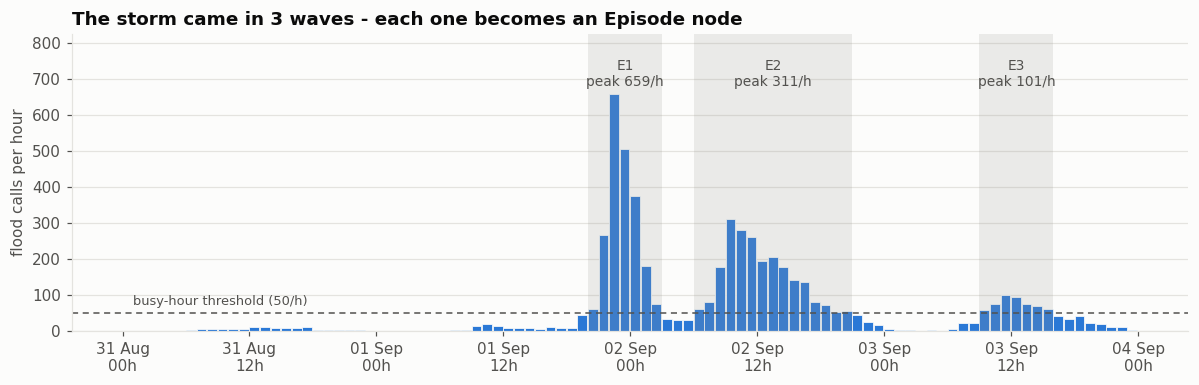

In [15]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(win.index, win.n_flood, width=1 / 24 * 0.92, align="edge", color=BLUE, edgecolor=SURF, linewidth=0.5)
for r in ep.itertuples():
    t0 = pd.Timestamp(r.start_ts, unit="s", tz="UTC").tz_convert(TZ); t1 = pd.Timestamp(r.end_ts, unit="s", tz="UTC").tz_convert(TZ)
    ax.axvspan(t0, t1, color="#9a9992", alpha=0.18, lw=0)
    ax.text(t0 + (t1 - t0) / 2, win.n_flood.max() * 1.02, f"{r.id}\npeak {r.peak_calls}/h", ha="center", va="bottom", fontsize=9, color=INK2)
ax.axhline(EPISODE_MIN, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(win.index[0] + pd.Timedelta(hours=1), EPISODE_MIN + 14, f"busy-hour threshold ({EPISODE_MIN}/h)", fontsize=8.5, color=INK2, ha="left", va="bottom")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12], tz=win.index.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Hh", tz=win.index.tz))
ax.set_ylim(0, win.n_flood.max() * 1.25); ax.set_ylabel("flood calls per hour")
ax.set_title(f"The storm came in {len(ep)} waves - each one becomes an Episode node")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 5.2 How much more happens during a wave? (`CO_SURGES_WITH`)

Average traffic-signal failures per hour **inside** waves vs **outside**. This becomes a property on the edge `flood → traffic_signal_failure`.

In [16]:
in_wave = win.episode_id.notna()
rate_in, rate_out = win.loc[in_wave, "n_signal"].mean(), win.loc[~in_wave, "n_signal"].mean()
cosurge = {"a": "flood", "b": "traffic_signal_failure",
           "per_hour_in_waves": round(float(rate_in), 2), "per_hour_outside": round(float(rate_out), 2),
           "ratio": round(float(rate_in / rate_out), 1) if rate_out > 0 else None}
print(f"traffic signal failures per hour: {cosurge['per_hour_in_waves']} inside waves vs {cosurge['per_hour_outside']} outside  ->  x{cosurge['ratio']}")

traffic signal failures per hour: 15.93 inside waves vs 2.96 outside  ->  x5.4


### 5.3 Node and relationship tables

In [17]:
def rows(frame):
    """DataFrame -> list of plain dicts (NaN -> None, numpy -> python), safe to send to Neo4j."""
    return json.loads(frame.to_json(orient="records"))

# ---- nodes ----
n_incident = rows(pd.DataFrame({"name": sorted(df.incident_type.unique())}))
n_calltype = rows(df[["call_type", "call_label", "call_group", "incident_type"]].drop_duplicates()
                    .rename(columns={"call_type": "name", "call_label": "label", "call_group": "call_group"}))
n_borough  = rows(pd.DataFrame({"name": sorted(df.borough.dropna().unique())}))
zones = (df[df.has_geo].groupby("zone_id")
           .agg(lat=("latitude", "mean"), lon=("longitude", "mean"),
                borough=("borough", lambda s: s.mode().iat[0] if s.notna().any() else None)).reset_index()
           .rename(columns={"zone_id": "id"}))
n_zone     = rows(zones)
n_window   = rows(win[["id", "n_flood", "n_signal", "n_total", "phase", "start_ts"]])
n_episode  = rows(ep)
n_call     = rows(df.rename(columns={"point_id": "id", "latitude": "lat", "longitude": "lon"})
                    [["id", "call_type", "surge_level", "city_recent_60m", "ts", "phase", "has_geo", "lat", "lon", "text"]])

# ---- relationships ----
r_instance = [{"a": r["name"], "b": r["incident_type"]} for r in n_calltype]
r_oftype   = rows(df[["point_id", "call_type"]].rename(columns={"point_id": "a", "call_type": "b"}))
r_inwindow = rows(pd.DataFrame({"a": df.point_id, "b": df.created_at.dt.floor("h").dt.strftime("%Y-%m-%dT%H")}))
r_inzone   = rows(df.loc[df.has_geo, ["point_id", "zone_id"]].rename(columns={"point_id": "a", "zone_id": "b"}))
r_inborough= rows(df.loc[df.borough.notna(), ["point_id", "borough"]].rename(columns={"point_id": "a", "borough": "b"}))
r_zone_b   = rows(zones.dropna(subset=["borough"])[["id", "borough"]].rename(columns={"id": "a", "borough": "b"}))
r_next     = [{"a": win.id.iloc[i], "b": win.id.iloc[i + 1]} for i in range(len(win) - 1)]
r_partof   = rows(win.loc[win.episode_id.notna(), ["id", "episode_id"]].rename(columns={"id": "a", "episode_id": "b"}))

plan = pd.DataFrame([
    ("nodes", "Call", len(n_call)), ("nodes", "CallType", len(n_calltype)), ("nodes", "IncidentType", len(n_incident)),
    ("nodes", "Window", len(n_window)), ("nodes", "Episode", len(n_episode)), ("nodes", "Zone", len(n_zone)), ("nodes", "Borough", len(n_borough)),
    ("rels", "OF_TYPE", len(r_oftype)), ("rels", "INSTANCE_OF", len(r_instance)), ("rels", "IN_WINDOW", len(r_inwindow)),
    ("rels", "NEXT", len(r_next)), ("rels", "PART_OF", len(r_partof)), ("rels", "IN_ZONE", len(r_inzone)),
    ("rels", "IN_BOROUGH", len(r_inborough) + len(r_zone_b)), ("rels", "CO_SURGES_WITH", 1),
], columns=["kind", "name", "to_load"])
print(f"{plan[plan.kind == 'nodes'].to_load.sum():,} nodes and {plan[plan.kind == 'rels'].to_load.sum():,} relationships will be created")
plan

7,075 nodes and 25,661 relationships will be created


,kind,name,to_load
0,nodes,Call,6273
1,nodes,CallType,5
2,nodes,IncidentType,2
3,nodes,Window,96
4,nodes,Episode,3
5,nodes,Zone,691
6,nodes,Borough,5
7,rels,OF_TYPE,6273
8,rels,INSTANCE_OF,5
9,rels,IN_WINDOW,6273


## 6 · Connect to Neo4j (Aura / your cloud instance)

Add these in Colab **Secrets** (left sidebar, key icon) and switch on *Notebook access*:

| Secret | Example |
|---|---|
| `NEO4J_URI` | `neo4j+s://xxxxxxxx.databases.neo4j.io` |
| `NEO4J_USERNAME` | `neo4j` |
| `NEO4J_PASSWORD` | the password from the Aura credentials file |
| `NEO4J_DATABASE` | *(optional)* default `neo4j` |

If a secret is missing, the cell asks for it (the password is typed hidden). Nothing is stored in the notebook.
An Aura Free instance that was idle may be **paused** - resume it in the Aura console first.

In [18]:
import subprocess, sys

def secret(name, prompt, hidden=False, default=None):
    """Colab Secrets -> environment variable -> prompt."""
    import getpass
    val = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            val = userdata.get(name)
        except Exception:
            val = None
    val = val or os.environ.get(name)
    if not val and default is None:
        val = (getpass.getpass if hidden else input)(prompt + ": ")
    return (val or default).strip()

_driver, NEO4J_DB = None, "neo4j"

def get_driver():
    """Create the Neo4j driver once and reuse it."""
    global _driver, NEO4J_DB
    if _driver is None:
        try:
            import neo4j  # noqa: F401
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "neo4j"], check=True)
        from neo4j import GraphDatabase
        uri  = secret("NEO4J_URI", "Neo4j URI (neo4j+s://...)")
        user = secret("NEO4J_USERNAME", "Neo4j username", default="neo4j")
        pwd  = secret("NEO4J_PASSWORD", "Neo4j password", hidden=True)
        NEO4J_DB = secret("NEO4J_DATABASE", "", default="neo4j")
        drv = GraphDatabase.driver(uri, auth=(user, pwd))
        try:
            drv.verify_connectivity()
        except Exception as e:
            raise RuntimeError(f"Could not connect to Neo4j at {uri}. Is the Aura instance running (not paused)? "
                               f"Check URI / user / password. Original error: {e}")
        _driver = drv
    return _driver

def q(query, **params):
    """Run a read query, return a list of plain dicts."""
    with get_driver().session(database=NEO4J_DB) as s:
        return [r.data() for r in s.run(query, **params)]

def q_raw(query, **params):
    """Run a query and keep the driver objects (nodes / paths) - used for drawing."""
    with get_driver().session(database=NEO4J_DB) as s:
        return list(s.run(query, **params))

if RUN_NEO4J:
    get_driver()
    print("Connected to Neo4j. Database:", NEO4J_DB)
    print("Nodes already in it:", q("MATCH (n) RETURN count(n) AS n")[0]["n"])
else:
    print("RUN_NEO4J is False - skipping the connection.")

Connected to Neo4j. Database: <your-aura-db>
Nodes already in it: 12156


## 7 · Load the graph

* Every node gets a **uniqueness constraint** on its key (this also creates the index that makes the loads fast).
* Everything uses `MERGE`, so **running it twice does not duplicate anything**.
* Every node created here is tagged `ds = "nyc311-ida"`. `CLEAR_GRAPH = True` deletes **only** nodes with that tag, never the rest of your database.

In [19]:
CONSTRAINTS = [
    ("Call", "id"), ("CallType", "name"), ("IncidentType", "name"), ("Window", "id"),
    ("Episode", "id"), ("Zone", "id"), ("Borough", "name"),
]

def clear_graph():
    total = 0
    with get_driver().session(database=NEO4J_DB) as s:
        while True:
            n = s.run("MATCH (n {ds: $ds}) WITH n LIMIT 5000 DETACH DELETE n RETURN count(*) AS n", ds=DS).single()["n"]
            total += n
            if n == 0:
                break
    print(f"deleted {total:,} nodes tagged ds = '{DS}'")

def load(query, data, size=1000, **extra):
    """Send `data` to Neo4j in batches; `query` must start with UNWIND $rows AS r."""
    with get_driver().session(database=NEO4J_DB) as s:
        for i in range(0, len(data), size):
            s.run(query, rows=data[i:i + size], ds=DS, **extra).consume()

def load_rel(rel, a_label, a_key, b_label, b_key, data, size=2000):
    load(f"UNWIND $rows AS r MATCH (a:{a_label} {{{a_key}: r.a}}), (b:{b_label} {{{b_key}: r.b}}) MERGE (a)-[:{rel}]->(b)", data, size)

Q_INCIDENT = "UNWIND $rows AS r MERGE (i:IncidentType {name: r.name}) SET i.ds = $ds"
Q_CALLTYPE = "UNWIND $rows AS r MERGE (t:CallType {name: r.name}) SET t.label = r.label, t.call_group = r.call_group, t.ds = $ds"
Q_BOROUGH  = "UNWIND $rows AS r MERGE (b:Borough {name: r.name}) SET b.ds = $ds"
Q_ZONE     = "UNWIND $rows AS r MERGE (z:Zone {id: r.id}) SET z.lat = r.lat, z.lon = r.lon, z.ds = $ds"
Q_WINDOW   = ("UNWIND $rows AS r MERGE (w:Window {id: r.id}) "
              "SET w.n_flood = r.n_flood, w.n_signal = r.n_signal, w.n_total = r.n_total, w.phase = r.phase, w.start_ts = r.start_ts, w.ds = $ds")
Q_EPISODE  = ("UNWIND $rows AS r MERGE (e:Episode {id: r.id}) "
              "SET e.start = r.start, e.end = r.end, e.hours = r.hours, e.peak_calls = r.peak_calls, e.peak_window = r.peak_window, "
              "e.total_calls = r.total_calls, e.top_borough = r.top_borough, e.start_ts = r.start_ts, e.end_ts = r.end_ts, e.ds = $ds")
Q_CALL     = ("UNWIND $rows AS r MERGE (c:Call {id: r.id}) "
              "SET c.call_type = r.call_type, c.surge_level = r.surge_level, c.city_recent_60m = r.city_recent_60m, c.ts = r.ts, "
              "c.phase = r.phase, c.has_geo = r.has_geo, c.lat = r.lat, c.lon = r.lon, c.text = r.text, c.ds = $ds")
Q_COSURGE  = ("MATCH (a:IncidentType {name: $a}), (b:IncidentType {name: $b}) MERGE (a)-[r:CO_SURGES_WITH]->(b) "
              "SET r.per_hour_in_waves = $pin, r.per_hour_outside = $pout, r.ratio = $ratio")

def load_graph():
    with get_driver().session(database=NEO4J_DB) as s:
        for label, key in CONSTRAINTS:
            s.run(f"CREATE CONSTRAINT {label.lower()}_{key} IF NOT EXISTS FOR (n:{label}) REQUIRE n.{key} IS UNIQUE").consume()
    if CLEAR_GRAPH:
        clear_graph()
    # nodes
    load(Q_INCIDENT, n_incident); load(Q_CALLTYPE, n_calltype); load(Q_BOROUGH, n_borough)
    load(Q_ZONE, n_zone); load(Q_WINDOW, n_window); load(Q_EPISODE, n_episode); load(Q_CALL, n_call)
    # relationships
    load_rel("INSTANCE_OF", "CallType", "name", "IncidentType", "name", r_instance)
    load_rel("IN_BOROUGH", "Zone", "id", "Borough", "name", r_zone_b)
    load_rel("NEXT", "Window", "id", "Window", "id", r_next)
    load_rel("PART_OF", "Window", "id", "Episode", "id", r_partof)
    load_rel("OF_TYPE", "Call", "id", "CallType", "name", r_oftype)
    load_rel("IN_WINDOW", "Call", "id", "Window", "id", r_inwindow)
    load_rel("IN_ZONE", "Call", "id", "Zone", "id", r_inzone)
    load_rel("IN_BOROUGH", "Call", "id", "Borough", "name", r_inborough)
    with get_driver().session(database=NEO4J_DB) as s:
        s.run(Q_COSURGE, a=cosurge["a"], b=cosurge["b"], pin=cosurge["per_hour_in_waves"],
              pout=cosurge["per_hour_outside"], ratio=cosurge["ratio"]).consume()

if RUN_NEO4J:
    load_graph()
    got_nodes = {r["label"]: r["n"] for r in q("MATCH (n {ds: $ds}) RETURN labels(n)[0] AS label, count(*) AS n ORDER BY n DESC", ds=DS)}
    got_rels  = {r["rel"]: r["n"] for r in q("MATCH ({ds: $ds})-[r]->() RETURN type(r) AS rel, count(*) AS n ORDER BY n DESC", ds=DS)}
    check = plan.copy()
    check["in_neo4j"] = [got_nodes.get(n, 0) if k == "nodes" else got_rels.get(n, 0) for k, n in zip(check.kind, check.name)]
    check["ok"] = check.in_neo4j >= check.to_load
    display(check)
    assert check.ok.all(), "Some counts are lower than expected - see the table above"
    print("Graph loaded and verified.")
else:
    print("RUN_NEO4J is False - skipping the load.")

deleted 7,075 nodes tagged ds = 'nyc311-ida'


,kind,name,to_load,in_neo4j,ok
0,nodes,Call,6273,6273,True
1,nodes,CallType,5,5,True
2,nodes,IncidentType,2,2,True
3,nodes,Window,96,96,True
4,nodes,Episode,3,3,True
5,nodes,Zone,691,691,True
6,nodes,Borough,5,5,True
7,rels,OF_TYPE,6273,6273,True
8,rels,INSTANCE_OF,5,5,True
9,rels,IN_WINDOW,6273,6273,True


Graph loaded and verified.


## 8 · Ask the graph questions (Cypher)

These are the kind of questions the vectors cannot answer.

In [20]:
if RUN_NEO4J:
    print("Surge waves:")
    display(pd.DataFrame(q("""
        MATCH (e:Episode) RETURN e.id AS wave, e.start AS start, e.end AS end, e.hours AS hours,
               e.peak_calls AS peak_calls_per_h, e.peak_window AS peak_hour, e.total_calls AS flood_calls, e.top_borough AS top_borough
        ORDER BY wave""")))

    print("Does another incident type surge together with flooding?")
    display(pd.DataFrame(q("""
        MATCH (a:IncidentType)-[r:CO_SURGES_WITH]->(b:IncidentType)
        RETURN a.name AS when_this_surges, b.name AS this_also_rises, r.per_hour_outside AS per_hour_normally,
               r.per_hour_in_waves AS per_hour_in_waves, r.ratio AS times_higher""")))

    print("Busiest 1 km zones during wave E1:")
    display(pd.DataFrame(q("""
        MATCH (z:Zone)<-[:IN_ZONE]-(c:Call)-[:IN_WINDOW]->(:Window)-[:PART_OF]->(:Episode {id: 'E1'})
        MATCH (z)-[:IN_BOROUGH]->(b:Borough)
        RETURN z.id AS zone, b.name AS borough, count(c) AS calls ORDER BY calls DESC LIMIT 8""")))
else:
    print("RUN_NEO4J is False.")

Surge waves:


,wave,start,end,hours,peak_calls_per_h,peak_hour,flood_calls,top_borough
0,E1,01 Sep 20:00,02 Sep 03:00,7,659,01 Sep 22:00,2121,Queens
1,E2,02 Sep 06:00,02 Sep 21:00,15,311,02 Sep 09:00,2284,Queens
2,E3,03 Sep 09:00,03 Sep 16:00,7,101,03 Sep 11:00,530,Queens


Does another incident type surge together with flooding?


,when_this_surges,this_also_rises,per_hour_normally,per_hour_in_waves,times_higher
0,flood,traffic_signal_failure,2.96,15.93,5.4


Busiest 1 km zones during wave E1:


,zone,borough,calls
0,z4062_-7414,Staten Island,30
1,z4074_-7382,Queens,29
2,z4062_-7416,Staten Island,25
3,z4062_-7394,Brooklyn,23
4,z4073_-7390,Queens,21
5,z4076_-7388,Queens,19
6,z4069_-7392,Brooklyn,19
7,z4061_-7411,Staten Island,19


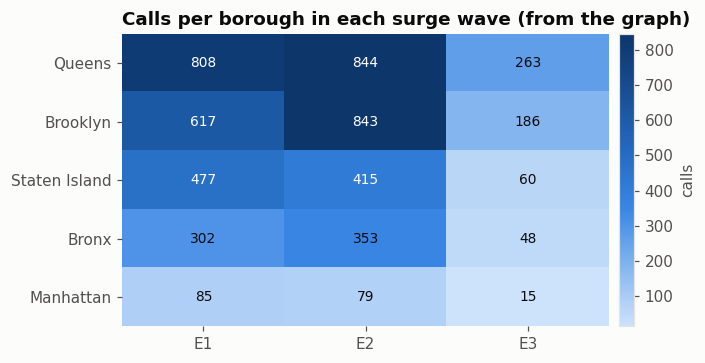

In [21]:
if RUN_NEO4J:
    t = pd.DataFrame(q("""
        MATCH (e:Episode)<-[:PART_OF]-(:Window)<-[:IN_WINDOW]-(c:Call)-[:IN_BOROUGH]->(b:Borough)
        RETURN e.id AS wave, b.name AS borough, count(c) AS calls"""))
    hm = t.pivot(index="borough", columns="wave", values="calls").fillna(0).astype(int)
    hm = hm.loc[hm.sum(axis=1).sort_values(ascending=False).index]

    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    im = ax.imshow(hm.values, cmap=SEQ, aspect="auto")
    ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns)
    ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index)
    for (i, j), v in np.ndenumerate(hm.values):
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=9, color="white" if v > hm.values.max() * 0.45 else INK)
    ax.grid(False)
    for s_ in ax.spines.values(): s_.set_visible(False)
    ax.set_title("Calls per borough in each surge wave (from the graph)")
    fig.colorbar(im, ax=ax, label="calls", fraction=0.04, pad=0.02)
    plt.tight_layout(); plt.show()

## 9 · Explain one call

`facts(call_id)` collects everything the graph knows around a call, `describe()` turns it into a sentence, and `draw_explanation()` draws the neighbourhood.

Call: Sewer backup reported. Situation: extreme surge, 403 similar calls city-wide during the previous hour. 

Sewer backup (flood), extreme surge with 403 similar calls city-wide in the previous hour. It belongs to surge wave E1 (01 Sep 20:00 -> 02 Sep 03:00, peak 659 flood calls/h at 01 Sep 22:00, 2,121 flood calls in total). Location: Brooklyn, zone z4066_-7399 (5 other calls in the same 1 km zone that hour). Same borough, same hour: 215 flood. Context: traffic signal failure calls run 5.4x higher while flood is in a surge wave.


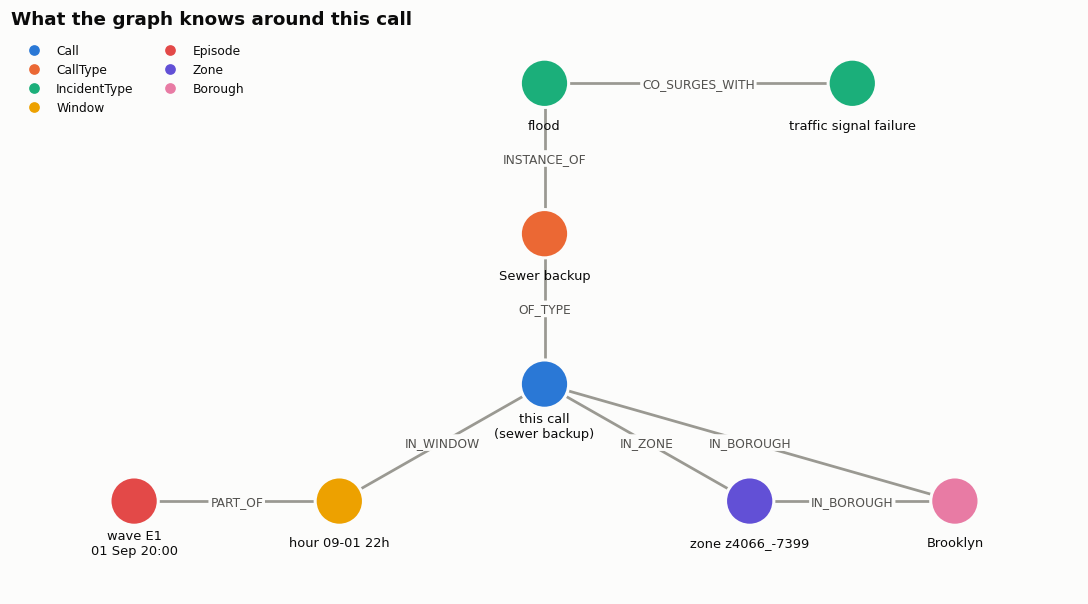

In [22]:
Q_FACTS = """
MATCH (c:Call {id: $id})-[:OF_TYPE]->(t:CallType)-[:INSTANCE_OF]->(i:IncidentType)
OPTIONAL MATCH (c)-[:IN_WINDOW]->(w:Window)
OPTIONAL MATCH (w)-[:PART_OF]->(e:Episode)
OPTIONAL MATCH (c)-[:IN_BOROUGH]->(b:Borough)
OPTIONAL MATCH (c)-[:IN_ZONE]->(z:Zone)
OPTIONAL MATCH (i)-[cs:CO_SURGES_WITH]-(:IncidentType)
RETURN c.surge_level AS surge_level, c.city_recent_60m AS recent, t.label AS call_label, i.name AS incident_type,
       w.id AS window, w.n_flood AS w_flood, w.n_signal AS w_signal, w.phase AS phase,
       e.id AS wave, e.start AS ep_start, e.end AS ep_end, e.peak_calls AS ep_peak, e.peak_window AS ep_peak_window, e.total_calls AS ep_total,
       b.name AS borough, z.id AS zone,
       startNode(cs).name AS cs_from, endNode(cs).name AS cs_to, cs.ratio AS cs_ratio
LIMIT 1
"""
Q_SAME_ZONE = """
MATCH (c:Call {id: $id})-[:IN_ZONE]->(z:Zone)<-[:IN_ZONE]-(o:Call)
MATCH (c)-[:IN_WINDOW]->(w:Window)<-[:IN_WINDOW]-(o)
WHERE o <> c
RETURN count(o) AS n
"""
Q_SAME_HOUR = """
MATCH (c:Call {id: $id})-[:IN_WINDOW]->(w:Window)
MATCH (c)-[:IN_BOROUGH]->(b:Borough)
MATCH (o:Call)-[:IN_WINDOW]->(w)
MATCH (o)-[:IN_BOROUGH]->(b)
MATCH (o)-[:OF_TYPE]->(:CallType)-[:INSTANCE_OF]->(i:IncidentType)
RETURN i.name AS incident_type, count(o) AS calls ORDER BY calls DESC
"""

def facts(call_id):
    rec = q(Q_FACTS, id=str(call_id))
    if not rec:
        return None
    f = rec[0]
    f["id"] = str(call_id)
    f["same_zone_same_hour"] = (q(Q_SAME_ZONE, id=str(call_id)) or [{"n": 0}])[0]["n"] if f.get("zone") else None
    f["same_hour_borough"]   = {r["incident_type"]: r["calls"] for r in q(Q_SAME_HOUR, id=str(call_id))} if f.get("borough") else {}
    return f

def describe(f):
    if f is None:
        return "(this id is not in the graph - run section 7 so the graph matches the Qdrant points)"
    s = f"{f['call_label']} ({f['incident_type'].replace('_', ' ')}), {f['surge_level']} with {f['recent']} similar calls city-wide in the previous hour"
    if f.get("wave"):
        s += (f". It belongs to surge wave {f['wave']} ({f['ep_start']} -> {f['ep_end']}, peak {f['ep_peak']} flood calls/h at {f['ep_peak_window']}, "
              f"{f['ep_total']:,} flood calls in total)")
    else:
        s += ". It is outside any surge wave"
    if f.get("borough"):
        s += f". Location: {f['borough']}"
        if f.get("zone"):
            s += f", zone {f['zone']} ({f['same_zone_same_hour']} other calls in the same 1 km zone that hour)"
        if f["same_hour_borough"]:
            s += ". Same borough, same hour: " + ", ".join(f"{n} {k.replace('_', ' ')}" for k, n in f["same_hour_borough"].items())
    else:
        s += ". Location unknown (no coordinates in the source)"
    if f.get("cs_ratio"):
        s += f". Context: {f['cs_to'].replace('_', ' ')} calls run {f['cs_ratio']}x higher while {f['cs_from'].replace('_', ' ')} is in a surge wave"
    return s + "."

Q_PATHS = """
MATCH (c:Call {id: $id})
OPTIONAL MATCH p1 = (c)-[:OF_TYPE]->(:CallType)-[:INSTANCE_OF]->(:IncidentType)
OPTIONAL MATCH p2 = (c)-[:IN_WINDOW]->(:Window)-[:PART_OF]->(:Episode)
OPTIONAL MATCH p3 = (c)-[:IN_ZONE]->(:Zone)-[:IN_BOROUGH]->(:Borough)
OPTIONAL MATCH p4 = (c)-[:OF_TYPE]->(:CallType)-[:INSTANCE_OF]->(:IncidentType)-[:CO_SURGES_WITH]-(:IncidentType)
OPTIONAL MATCH p5 = (c)-[:IN_BOROUGH]->(:Borough)
RETURN [p IN [p1, p2, p3, p4, p5] WHERE p IS NOT NULL | p] AS paths
"""
NODE_COLORS = {"Call": "#2a78d6", "CallType": "#eb6834", "IncidentType": "#1baf7a", "Window": "#eda100",
               "Episode": "#e34948", "Zone": "#6250d6", "Borough": "#e87ba4"}

def _node_key(n):
    return getattr(n, "element_id", None) or n.id

def _node_text(n):
    lab, p = next(iter(n.labels)), dict(n.items())
    return {"Call": "this call\n(" + str(p.get("call_type", "")).replace("_", " ") + ")", "CallType": p.get("label"),
            "IncidentType": str(p.get("name", "")).replace("_", " "),
            "Window": "hour " + str(p.get("id", ""))[5:].replace("T", " ") + "h", "Episode": f"wave {p.get('id')}\n{p.get('start', '')}",
            "Zone": f"zone {p.get('id')}", "Borough": p.get("name")}.get(lab, lab)

# fixed layout so the picture always reads the same way: type chain on top, time on the left, place on the right
LAYOUT_SLOTS = {"Call": [(0, 0)], "CallType": [(0, 1.8)], "IncidentType": [(0, 3.6), (3.0, 3.6), (-3.0, 3.6)],
                "Window": [(-2.0, -1.4)], "Episode": [(-4.0, -1.4)], "Zone": [(2.0, -1.4)], "Borough": [(4.0, -1.4)]}

def draw_explanation(call_id):
    recs = q_raw(Q_PATHS, id=str(call_id))
    if not recs:
        print("call not found"); return
    G, labels, kinds = nx.Graph(), {}, {}
    for path in recs[0]["paths"]:
        for n in path.nodes:
            k = _node_key(n); labels[k] = _node_text(n); kinds[k] = next(iter(n.labels)); G.add_node(k)
        for r in path.relationships:
            G.add_edge(_node_key(r.start_node), _node_key(r.end_node), label=r.type)
    used, pos = Counter(), {}
    for k in G.nodes:
        pos[k] = LAYOUT_SLOTS[kinds[k]][used[kinds[k]]]; used[kinds[k]] += 1
    fig, ax = plt.subplots(figsize=(10, 5.6))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9a9992", width=1.8)
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "label"), ax=ax, font_size=8, font_color=INK2, rotate=False,
                                 bbox=dict(boxstyle="round,pad=0.15", fc=SURF, ec="none"))
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[NODE_COLORS[kinds[k]] for k in G], node_size=1000, edgecolors=SURF, linewidths=2)
    nx.draw_networkx_labels(G, {k: (x, y - 0.5) for k, (x, y) in pos.items()}, labels, ax=ax, font_size=8.5, font_color=INK)
    handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in NODE_COLORS.items() if k in kinds.values()]
    ax.legend(handles=handles, loc="upper left", fontsize=8, ncol=2)
    ax.set_xlim(-5.2, 5.2); ax.set_ylim(-2.5, 4.2)
    ax.set_title("What the graph knows around this call"); ax.axis("off")
    plt.tight_layout(); plt.show()

if RUN_NEO4J:
    pick = df[(df.call_type == "sewer_backup") & (df.phase == "storm_night") & df.has_geo].iloc[len(df) // 20]
    print("Call:", pick.text, "\n")
    print(describe(facts(pick.point_id)))
    draw_explanation(pick.point_id)
else:
    print("RUN_NEO4J is False.")

## 10 · Combine: Qdrant finds similar calls, Neo4j explains them

For a new situation:

1. build the same generic sentence as in section 3 and embed it,
2. **Qdrant** returns the most similar past calls (and their `point_id`),
3. **Neo4j** is asked about each of those ids,
4. we print a per-call explanation and a short summary of what the matches have in common.

Set `RUN_COMBINE = True` in the first constants cell (section 0). It needs the Qdrant collection from section 4 and the graph from section 7 to exist, and your Qdrant and Neo4j secrets. If you ran section 4 in this same session, the embedding model and the Qdrant connection are reused.

In [23]:
def surge_label(n):
    return ("isolated report" if n <= 4 else "small cluster" if n <= 29 else
            "busy period" if n <= 99 else "heavy surge" if n <= 299 else "extreme surge")

def make_query_text(call_label, similar_calls):
    """Same sentence format as section 3."""
    return (f"{call_label} reported. Situation: {surge_label(similar_calls)}, "
            f"{similar_calls} similar calls city-wide during the previous hour.")

_qdrant = {}
QDRANT_COLLECTION = COLLECTION     # same collection as section 4

def get_qdrant():
    # reuse the connection and the embedding model from section 4 when that ran in this session
    if "client" not in _qdrant and globals().get("client") is not None and globals().get("model") is not None:
        _qdrant["client"], _qdrant["model"] = globals()["client"], globals()["model"]
    if "client" not in _qdrant:
        try:
            import sentence_transformers, qdrant_client  # noqa: F401
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers", "qdrant-client"], check=True)
        from sentence_transformers import SentenceTransformer
        from qdrant_client import QdrantClient
        url = secret("QDRANT_URL", "Qdrant URL").rstrip("/")
        key = secret("QDRANT_API_KEY", "Qdrant API key", hidden=True)
        _qdrant["client"] = QdrantClient(url=url, api_key=key, timeout=60)
        _qdrant["model"]  = SentenceTransformer(EMBED_MODEL)   # same model as section 4
    return _qdrant["client"], _qdrant["model"]

def explain_situation(text, k=8, verbose=True):
    client, model = get_qdrant()
    vec  = model.encode(text, normalize_embeddings=True).tolist()
    hits = client.query_points(QDRANT_COLLECTION, query=vec, limit=k, with_payload=True).points
    out  = []
    if verbose:
        print(f"\nNEW SITUATION: {text}\n")
    for rank, h in enumerate(hits, 1):
        f = facts(h.id)
        out.append((h, f))
        if verbose:
            print(f"{rank}. similarity {h.score:.3f} | Qdrant says: {h.payload['text']}")
            print(f"   Neo4j says: {describe(f)}\n")
    known = [f for _, f in out if f]
    if verbose and known:
        waves, boroughs = Counter(f["wave"] or "no wave" for f in known), Counter(f["borough"] or "unknown" for f in known)
        print("What the matches have in common (from the graph):")
        print("  surge waves:", ", ".join(f"{w} x{n}" for w, n in waves.most_common()))
        print("  boroughs   :", ", ".join(f"{b} x{n}" for b, n in boroughs.most_common()))
    return out

if RUN_COMBINE:
    explain_situation(make_query_text("Sewer backup", 350))       # a wave-peak situation
    explain_situation(make_query_text("Traffic signal failure", 12))  # a quiet-hour situation
else:
    print("RUN_COMBINE is False - skipping.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


NEW SITUATION: Sewer backup reported. Situation: extreme surge, 350 similar calls city-wide during the previous hour.

1. similarity 1.000 | Qdrant says: Sewer backup reported. Situation: extreme surge, 350 similar calls city-wide during the previous hour.
   Neo4j says: Sewer backup (flood), extreme surge with 350 similar calls city-wide in the previous hour. It belongs to surge wave E1 (01 Sep 20:00 -> 02 Sep 03:00, peak 659 flood calls/h at 01 Sep 22:00, 2,121 flood calls in total). Location: Brooklyn, zone z4066_-7390 (0 other calls in the same 1 km zone that hour). Same borough, same hour: 215 flood. Context: traffic signal failure calls run 5.4x higher while flood is in a surge wave.

2. similarity 1.000 | Qdrant says: Sewer backup reported. Situation: extreme surge, 350 similar calls city-wide during the previous hour.
   Neo4j says: Sewer backup (flood), extreme surge with 350 similar calls city-wide in the previous hour. It belongs to surge wave E1 (01 Sep 20:00 -> 02 Sep 03: